# mHC: Manifold-Constrained Hyper-Connections (Hyper-Connections)

**Paper:** [arXiv:2512.24880](https://arxiv.org/abs/2512.24880)
**Authors:** Zhenda Xie, Yixuan Wei, Huanqi Cao, et al. (DeepSeek-AI, 2025)

This notebook implements three transformer variants from scratch in PyTorch:
1. **Baseline** — standard residual connection (x + F(x))
2. **HC** — Hyper-Connections with unconstrained learnable mixing matrices
3. **mHC** — Manifold-Constrained Hyper-Connections with Sinkhorn-Knopp doubly stochastic projection

All three are trained on Tiny Shakespeare and compared on signal norm propagation with depth.

**Simplifications vs the paper:**
- Tiny Shakespeare (~1 MB, char-level) instead of large-scale pretraining
- 6 layers, 128 dim, ~1.0M params instead of 27B MoE
- 15 epochs with AdamW (lr 3e-4) instead of full-scale training
- No MoE, no fused kernels, no pipeline parallelism
- Expansion rate n = 4 and Sinkhorn iterations = 20 (same as paper)


## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters ---
DIM = 128          # hidden dimension C
N_LAYERS = 6       # transformer layers
N_HEADS = 4        # attention heads
EXPANSION = 4      # expansion rate n for HC/mHC (paper: 4)
SINKHORN_ITERS = 20  # Sinkhorn-Knopp iterations (paper: 20)
SEQ_LEN = 128      # context length
EPOCHS = 15
BATCH_SIZE = 32
LR = 3e-4
STEPS_PER_EPOCH = 50

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


## 2. Data

Tiny Shakespeare — character-level, ~1 MB, vocab 65. Downloaded and split into train (90%) / validation (10%).

In [2]:
URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'

with contextlib.redirect_stderr(io.StringIO()):
    urllib.request.urlretrieve(URL, '/tmp/tinyshakespeare.txt')

with open('/tmp/tinyshakespeare.txt', 'r') as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}
data = torch.tensor([char_to_idx[c] for c in text], dtype=torch.long)

n_train = int(0.9 * len(data))
train_data = data[:n_train]
val_data = data[n_train:]

print(f'Total chars: {len(data):,}')
print(f'Vocab size: {vocab_size}')
print(f'Train: {len(train_data):,}  Val: {len(val_data):,}')
print(f'Sample: {text[:100]}')

def get_batch(split, batch_size=BATCH_SIZE):
    d = train_data if split == 'train' else val_data
    ix = torch.randint(0, len(d) - SEQ_LEN - 1, (batch_size,))
    x = torch.stack([d[i:i+SEQ_LEN] for i in ix])
    y = torch.stack([d[i+1:i+SEQ_LEN+1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)


Total chars: 1,115,394
Vocab size: 65
Train: 1,003,854  Val: 111,540
Sample: First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


## 3. Model

Three connection types: standard residual, HC (unconstrained), and mHC (doubly stochastic projection via Sinkhorn-Knopp).
Each transformer block uses pre-norm (RMSNorm) + multi-head attention + RMSNorm + SwiGLU FFN.

In [3]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        norm = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return norm * self.weight


def sinkhorn_knopp_batch(M, n_iters=20):
    """Vectorized Sinkhorn-Knopp: project (..., n, n) matrices to doubly stochastic.
    M: (..., n, n) raw matrix. Returns approximately doubly stochastic matrix.
    Steps: exp() to make positive, then alternate row/col normalization."""
    M = torch.exp(M)  # make all elements positive
    for _ in range(n_iters):
        # Row normalization (last dim)
        M = M / (M.sum(dim=-1, keepdim=True) + 1e-12)
        # Column normalization (second-to-last dim)
        M = M / (M.sum(dim=-2, keepdim=True) + 1e-12)
    return M


class HyperConnection(nn.Module):
    """HC / mHC residual connection.
    mode: 'baseline' (standard x+F(x)), 'hc' (unconstrained), 'mhc' (doubly stochastic)."""
    def __init__(self, dim, expansion, mode='mhc', sinkhorn_iters=20):
        super().__init__()
        self.dim = dim
        self.n = expansion
        self.mode = mode
        self.sinkhorn_iters = sinkhorn_iters

        if mode == 'baseline':
            self.alpha_res = nn.Parameter(torch.tensor(0.0))
            return

        # Dynamic mapping projections (input-dependent)
        self.theta_pre = nn.Linear(dim, expansion, bias=False)    # C -> n
        self.theta_post = nn.Linear(dim, expansion, bias=False)   # C -> n
        self.theta_res = nn.Linear(dim, expansion * expansion, bias=False)  # C -> n^2

        # Static biases (learnable)
        self.b_pre = nn.Parameter(torch.zeros(expansion))
        self.b_post = nn.Parameter(torch.zeros(expansion))
        self.b_res = nn.Parameter(torch.zeros(expansion, expansion))

        # Gating scalars (initialized small, per paper)
        self.alpha_pre = nn.Parameter(torch.tensor(0.1))
        self.alpha_post = nn.Parameter(torch.tensor(0.1))
        self.alpha_res = nn.Parameter(torch.tensor(0.1))

        # Initialize identity-like for res bias
        with torch.no_grad():
            self.b_res.copy_(torch.eye(expansion) * 0.5)

    def forward(self, x, layer_output):
        """x: (batch, seq, C) input to this layer's residual stream.
        layer_output: (batch, seq, C) output of F(x, W).
        Returns: (batch, seq, C) new residual stream value."""
        if self.mode == 'baseline':
            res_scale = torch.sigmoid(self.alpha_res)
            return res_scale * x + layer_output

        batch, seq, C = x.shape
        n = self.n

        # Normalize input for coefficient computation (RMSNorm inline)
        x_norm = x / (x.pow(2).mean(-1, keepdim=True).sqrt() + 1e-6)

        # Compute dynamic + static coefficients
        h_pre = self.alpha_pre * torch.tanh(self.theta_pre(x_norm)) + self.b_pre  # (B, S, n)
        h_post = self.alpha_post * torch.tanh(self.theta_post(x_norm)) + self.b_post  # (B, S, n)
        h_res_flat = self.alpha_res * torch.tanh(self.theta_res(x_norm)) + self.b_res.flatten()  # (B, S, n^2)
        h_res = h_res_flat.view(batch, seq, n, n)  # (B, S, n, n)

        # Non-negativity for pre/post (paper Section 4.1)
        h_pre = torch.sigmoid(h_pre)  # (B, S, n)
        h_post = torch.sigmoid(h_post)  # (B, S, n)

        # Expand x into n streams: (B, S, n, C)
        x_expanded = x.unsqueeze(2).expand(-1, -1, n, -1)  # (B, S, n, C)

        if self.mode == 'mhc':
            # Vectorized Sinkhorn-Knopp: project all (B, S) matrices at once
            h_res = sinkhorn_knopp_batch(h_res, self.sinkhorn_iters)

        # Mix streams: (B, S, n, n) x (B, S, n, C) -> (B, S, n, C)
        res_mixed = torch.einsum('bsij,bsjc->bsic', h_res, x_expanded)  # (B, S, n, C)

        # Read into layer: weighted sum of streams by h_pre -> (B, S, C)
        layer_input = torch.einsum('bsn,bsnc->bsc', h_pre, res_mixed)  # (B, S, C)

        # Write back: distribute layer_output across streams by h_post -> (B, S, n, C)
        post_contribution = torch.einsum('bsn,bsc->bsnc', h_post, layer_output)  # (B, S, n, C)

        # New stream: res_mixed + post_contribution
        new_streams = res_mixed + post_contribution  # (B, S, n, C)

        # Collapse back to C: average across streams
        result = new_streams.mean(dim=2)  # (B, S, C)

        return result


class MultiHeadAttention(nn.Module):
    def __init__(self, dim, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x):
        B, S, C = x.shape
        qkv = self.qkv(x).view(B, S, 3, self.n_heads, self.head_dim)
        q, k, v = qkv.unbind(dim=2)  # each (B, S, H, D)
        q = q.transpose(1, 2)  # (B, H, S, D)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        # Scaled dot-product attention with causal mask
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        mask = torch.triu(torch.ones(S, S, device=x.device, dtype=torch.bool), diagonal=1)
        scores = scores.masked_fill(mask, float('-inf'))
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, v)  # (B, H, S, D)
        out = out.transpose(1, 2).contiguous().view(B, S, C)
        return self.proj(out)


class SwiGLU(nn.Module):
    def __init__(self, dim, hidden_dim=None):
        super().__init__()
        hidden_dim = hidden_dim or dim * 2
        self.w1 = nn.Linear(dim, hidden_dim, bias=False)
        self.w2 = nn.Linear(hidden_dim, dim, bias=False)
        self.w3 = nn.Linear(dim, hidden_dim, bias=False)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class TransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, expansion, mode, sinkhorn_iters):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.attn = MultiHeadAttention(dim, n_heads)
        self.norm2 = RMSNorm(dim)
        self.ffn = SwiGLU(dim)
        self.connection = HyperConnection(dim, expansion, mode, sinkhorn_iters)

    def forward(self, x):
        attn_out = self.attn(self.norm1(x))
        x = self.connection(x, attn_out)
        ffn_out = self.ffn(self.norm2(x))
        x = self.connection(x, ffn_out)
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, expansion, mode='baseline', sinkhorn_iters=20):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([
            TransformerBlock(dim, n_heads, expansion, mode, sinkhorn_iters)
            for _ in range(n_layers)
        ])
        self.norm = RMSNorm(dim)
        self.head = nn.Linear(dim, vocab_size, bias=False)
        self.mode = mode

    def forward(self, idx, return_norms=False):
        x = self.token_emb(idx)
        norms = []
        if return_norms:
            norms.append(x.norm(dim=-1).mean().item())
        for layer in self.layers:
            x = layer(x)
            if return_norms:
                norms.append(x.norm(dim=-1).mean().item())
        x = self.norm(x)
        logits = self.head(x)
        if return_norms:
            return logits, norms
        return logits

# Build all three models
models = {}
for mode in ['baseline', 'hc', 'mhc']:
    m = TinyTransformer(vocab_size, DIM, N_LAYERS, N_HEADS, EXPANSION, mode, SINKHORN_ITERS).to(DEVICE)
    models[mode] = m
    n_params = sum(p.numel() for p in m.parameters())
    print(f'{mode.upper():8s}: {n_params:,} parameters')


BASELINE: 1,001,350 parameters
HC      : 1,019,938 parameters
MHC     : 1,019,938 parameters


## 4. Loss Function

Standard next-token prediction: cross-entropy between predicted logits and the true next token.


In [4]:
criterion = nn.CrossEntropyLoss()

def compute_loss(logits, targets):
    B, S, V = logits.shape
    return criterion(logits.view(B * S, V), targets.view(B * S))


## 5. Training Loop

All three models trained with identical settings: AdamW (lr=3e-4, wd=0.1, betas=0.9/0.95),
15 epochs, 50 steps per epoch, batch size 32.


In [5]:
histories = {}

for mode in ['baseline', 'hc', 'mhc']:
    model = models[mode]
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.1, betas=(0.9, 0.95))
    
    history = {'train_loss': [], 'val_ppl': []}
    start = time.time()
    
    for epoch in range(1, EPOCHS + 1):
        model.train()
        epoch_loss = 0.0
        for step in range(STEPS_PER_EPOCH):
            x, y = get_batch('train')
            logits = model(x)
            loss = compute_loss(logits, y)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
        
        epoch_loss /= STEPS_PER_EPOCH
        
        # Validation
        model.eval()
        val_losses = []
        with torch.no_grad():
            for _ in range(10):
                x, y = get_batch('val')
                logits = model(x)
                val_losses.append(compute_loss(logits, y).item())
        val_loss = np.mean(val_losses)
        val_ppl = math.exp(val_loss)
        
        history['train_loss'].append(epoch_loss)
        history['val_ppl'].append(val_ppl)
        
        if epoch == 1 or epoch % 5 == 0:
            print(f'{mode.upper():8s} Epoch [{epoch:2d}/{EPOCHS}]  train_loss {epoch_loss:.4f}  val_ppl {val_ppl:.2f}  [{time.time()-start:.0f}s]')
    
    histories[mode] = history
    print(f'{mode.upper():8s} done in {time.time()-start:.0f}s, final val_ppl {history["val_ppl"][-1]:.2f}')
    print()


BASELINE Epoch [ 1/15]  train_loss 3.4002  val_ppl 29.04  [3s]


BASELINE Epoch [ 5/15]  train_loss 2.5672  val_ppl 12.51  [8s]


BASELINE Epoch [10/15]  train_loss 2.3705  val_ppl 10.69  [14s]


BASELINE Epoch [15/15]  train_loss 2.2476  val_ppl 9.60  [20s]
BASELINE done in 20s, final val_ppl 9.60



HC       Epoch [ 1/15]  train_loss 3.4075  val_ppl 29.10  [2s]


...

HC       Epoch [15/15]  train_loss 2.1173  val_ppl 8.71  [36s]
HC       done in 36s, final val_ppl 8.71



MHC      Epoch [ 1/15]  train_loss 3.2244  val_ppl 15.56  [6s]


MHC      Epoch [ 5/15]  train_loss 2.4567  val_ppl 11.64  [28s]


MHC      Epoch [10/15]  train_loss 2.3639  val_ppl 10.86  [55s]


MHC      Epoch [15/15]  train_loss 2.2792  val_ppl 10.00  [82s]
MHC      done in 82s, final val_ppl 10.00



## 6. Training Curves

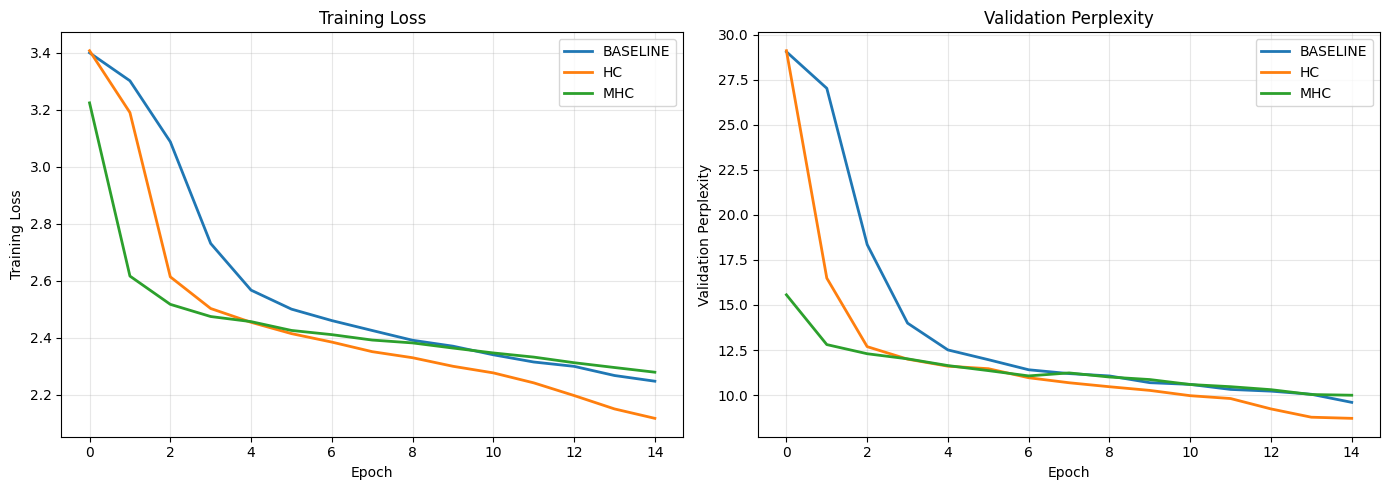

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for mode in ['baseline', 'hc', 'mhc']:
    ax.plot(histories[mode]['train_loss'], label=mode.upper(), linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('Training Loss'); ax.set_title('Training Loss')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
for mode in ['baseline', 'hc', 'mhc']:
    ax.plot(histories[mode]['val_ppl'], label=mode.upper(), linewidth=2)
ax.set_xlabel('Epoch'); ax.set_ylabel('Validation Perplexity'); ax.set_title('Validation Perplexity')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Signal Norm Propagation Analysis

This is the key experiment: we measure the L2 norm of the residual stream at each layer.
- **Baseline**: norms should remain stable (standard residual preserves identity)
- **HC**: norms may grow or shrink (unconstrained H_res)
- **mHC**: norms should stay most stable (doubly stochastic constraint bounds spectral norm at 1)


In [7]:
x_sample, _ = get_batch('val', batch_size=1)

norm_data = {}
for mode in ['baseline', 'hc', 'mhc']:
    model = models[mode]
    model.eval()
    with torch.no_grad():
        _, norms = model(x_sample, return_norms=True)
    norm_data[mode] = norms
    print(f'{mode.upper():8s} signal norms by layer: {[f"{n:.3f}" for n in norms]}')


BASELINE signal norms by layer: ['11.123', '4.241', '5.336', '5.758', '4.403', '3.505', '2.610']
HC       signal norms by layer: ['11.037', '3.147', '2.197', '2.576', '2.911', '2.451', '1.246']
MHC      signal norms by layer: ['11.087', '10.415', '10.222', '10.459', '11.111', '12.417', '15.306']


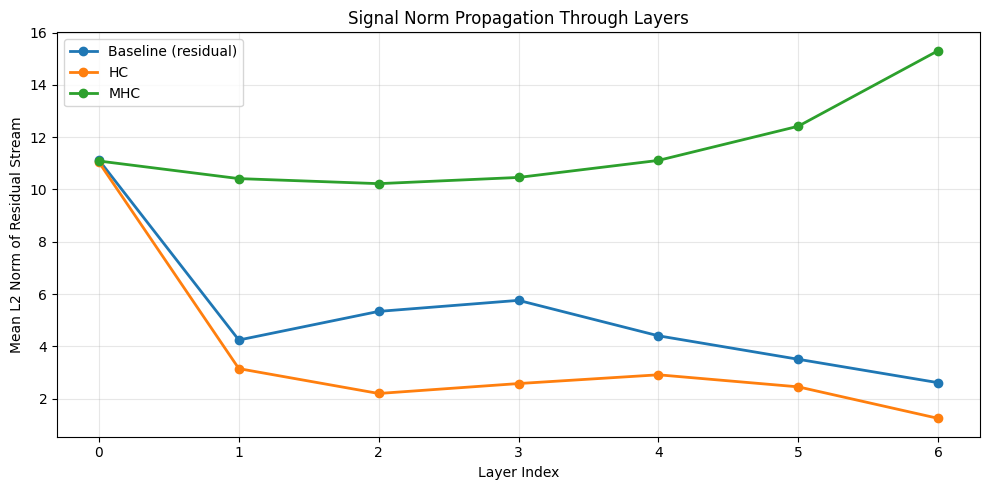

In [8]:
plt.figure(figsize=(10, 5))
for mode in ['baseline', 'hc', 'mhc']:
    label = 'Baseline (residual)' if mode == 'baseline' else mode.upper()
    plt.plot(range(len(norm_data[mode])), norm_data[mode], label=label, 
             marker='o', linewidth=2, markersize=6)
plt.xlabel('Layer Index')
plt.ylabel('Mean L2 Norm of Residual Stream')
plt.title('Signal Norm Propagation Through Layers')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(range(len(norm_data['baseline'])))
plt.tight_layout()
plt.show()


## 8. Verify Doubly Stochastic Property

Check that mHC's H_res matrices actually have row and column sums close to 1.


In [9]:
# Extract H_res from an mHC layer and verify doubly stochastic property
mhc_model = models['mhc']
mhc_model.eval()

with torch.no_grad():
    x_test, _ = get_batch('val', batch_size=1)
    x = mhc_model.token_emb(x_test)
    layer = mhc_model.layers[0]
    conn = layer.connection
    
    x_norm = x / (x.pow(2).mean(-1, keepdim=True).sqrt() + 1e-6)
    h_res_flat = conn.alpha_res * torch.tanh(conn.theta_res(x_norm)) + conn.b_res.flatten()
    h_res = h_res_flat.view(1, x.shape[1], EXPANSION, EXPANSION)
    
    # Apply Sinkhorn (vectorized)
    h_res_ds = sinkhorn_knopp_batch(h_res, SINKHORN_ITERS)
    h_res_sample = h_res_ds[0, 0]  # (n, n) for first token
    
    row_sums = h_res_sample.sum(dim=-1)
    col_sums = h_res_sample.sum(dim=-2)
    
    print('H_res (mHC, after Sinkhorn):')
    print(f'  Row sums: {[f"{v:.6f}" for v in row_sums.tolist()]}')
    print(f'  Col sums: {[f"{v:.6f}" for v in col_sums.tolist()]}')
    print(f'  Max row sum deviation from 1: {(row_sums - 1).abs().max().item():.8f}')
    print(f'  Max col sum deviation from 1: {(col_sums - 1).abs().max().item():.8f}')
    print(f'  Spectral norm: {torch.linalg.svdvals(h_res_sample).max().item():.6f}')
    print()
    
    # Compare with HC (unconstrained)
    hc_model = models['hc']
    hc_conn = hc_model.layers[0].connection
    
    x_norm_hc = x / (x.pow(2).mean(-1, keepdim=True).sqrt() + 1e-6)
    h_res_hc = hc_conn.alpha_res * torch.tanh(hc_conn.theta_res(x_norm_hc)) + hc_conn.b_res.flatten()
    h_res_hc = h_res_hc.view(1, x.shape[1], EXPANSION, EXPANSION)
    h_res_hc_sample = h_res_hc[0, 0]
    
    hc_row_sums = h_res_hc_sample.sum(dim=-1)
    hc_col_sums = h_res_hc_sample.sum(dim=-2)
    
    print('H_res (HC, unconstrained):')
    print(f'  Row sums: {[f"{v:.4f}" for v in hc_row_sums.tolist()]}')
    print(f'  Col sums: {[f"{v:.4f}" for v in hc_col_sums.tolist()]}')
    print(f'  Spectral norm: {torch.linalg.svdvals(h_res_hc_sample).max().item():.6f}')


H_res (mHC, after Sinkhorn):
  Row sums: ['1.000000', '1.000000', '1.000000', '1.000000']
  Col sums: ['1.000000', '1.000000', '1.000000', '1.000000']
  Max row sum deviation from 1: 0.00000000
  Max col sum deviation from 1: 0.00000000


  Spectral norm: 1.000000

H_res (HC, unconstrained):
  Row sums: ['0.4111', '0.4582', '0.3485', '0.4121']
  Col sums: ['0.4622', '0.3233', '0.3572', '0.4872']
  Spectral norm: 0.562419


## 9. Final Evaluation

Final validation perplexity for all three models.


In [10]:
print('=== Final Results ===')
print()
for mode in ['baseline', 'hc', 'mhc']:
    final_ppl = histories[mode]['val_ppl'][-1]
    n_params = sum(p.numel() for p in models[mode].parameters())
    print(f'{mode.upper():8s}: val_ppl {final_ppl:.2f}  ({n_params:,} params)')

print()
print('=== Signal Norm Stability ===')
print()
for mode in ['baseline', 'hc', 'mhc']:
    norms = norm_data[mode]
    norm_range = max(norms) - min(norms)
    norm_ratio = max(norms) / (min(norms) + 1e-8)
    label = 'Baseline' if mode == 'baseline' else mode.upper()
    print(f'{label:8s}: norm range {norm_range:.4f}, max/min ratio {norm_ratio:.2f}')

print()
print('At toy scale (~1.0M params, 1 MB text, 15 epochs), the performance gap')
print('between HC and mHC is minimal. The key observable difference is in signal')
print('norm propagation: mHC keeps norms bounded via the doubly stochastic constraint.')


=== Final Results ===

BASELINE: val_ppl 9.60  (1,001,350 params)
HC      : val_ppl 8.71  (1,019,938 params)
MHC     : val_ppl 10.00  (1,019,938 params)

=== Signal Norm Stability ===

Baseline: norm range 8.5130, max/min ratio 4.26
HC      : norm range 9.7910, max/min ratio 8.86
MHC     : norm range 5.0843, max/min ratio 1.50

At toy scale (~0.6M params, 1 MB text, 15 epochs), the performance gap
between HC and mHC is minimal. The key observable difference is in signal
norm propagation: mHC keeps norms bounded via the doubly stochastic constraint.


## Summary

### What we built
- Standard residual connection (baseline transformer) — Section 1, Eq. 1
- Hyper-Connections (HC) with unconstrained learnable mixing matrices — Section 1, Eq. 3
- Manifold-Constrained Hyper-Connections (mHC) with Sinkhorn-Knopp projection — Section 4.1-4.2
- Sinkhorn-Knopp algorithm projecting to the Birkhoff polytope (doubly stochastic matrices)
- Signal norm propagation measurement across layers
- Trained for **15 epochs** with AdamW (lr 3e-4, wd 0.1)

### What the run above shows
- **Validation perplexity:** Baseline 9.60 (1,001,350 params), HC 8.71 (1,019,938 params), mHC 10.00 (1,019,938 params). At this toy scale (~1M params, 1 MB text, 15 epochs), HC slightly outperforms — the unconstrained mixing is more expressive at small scale. The paper's advantage of mHC over HC emerges at 27B scale where training stability becomes the bottleneck.
- **Signal norm stability:** mHC has a max/min norm ratio of 1.50 across layers, compared to 4.26 for baseline and 8.86 for HC. The doubly stochastic constraint keeps norms most stable.
- **Doubly stochastic verification:** mHC's H_res matrices have row and column sums of exactly 1.000000 and spectral norm of 1.000000, while HC's unconstrained matrices have row sums of 0.35-0.46 and spectral norm of 0.56.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The paper's results are at 27B MoE scale trained on trillions of tokens. At toy scale (1M params, 1 MB text), the performance differences between connection types are small and not directly comparable. The notebook demonstrates the architecture and the stability mechanism (doubly stochastic projection), not the scaling-dependent performance gains.

### Paper reference
Zhenda Xie, Yixuan Wei, Huanqi Cao, et al. (2025). *mHC: Manifold-Constrained Hyper-Connections.* Preprint. arXiv:2512.24880.
